# Gemma

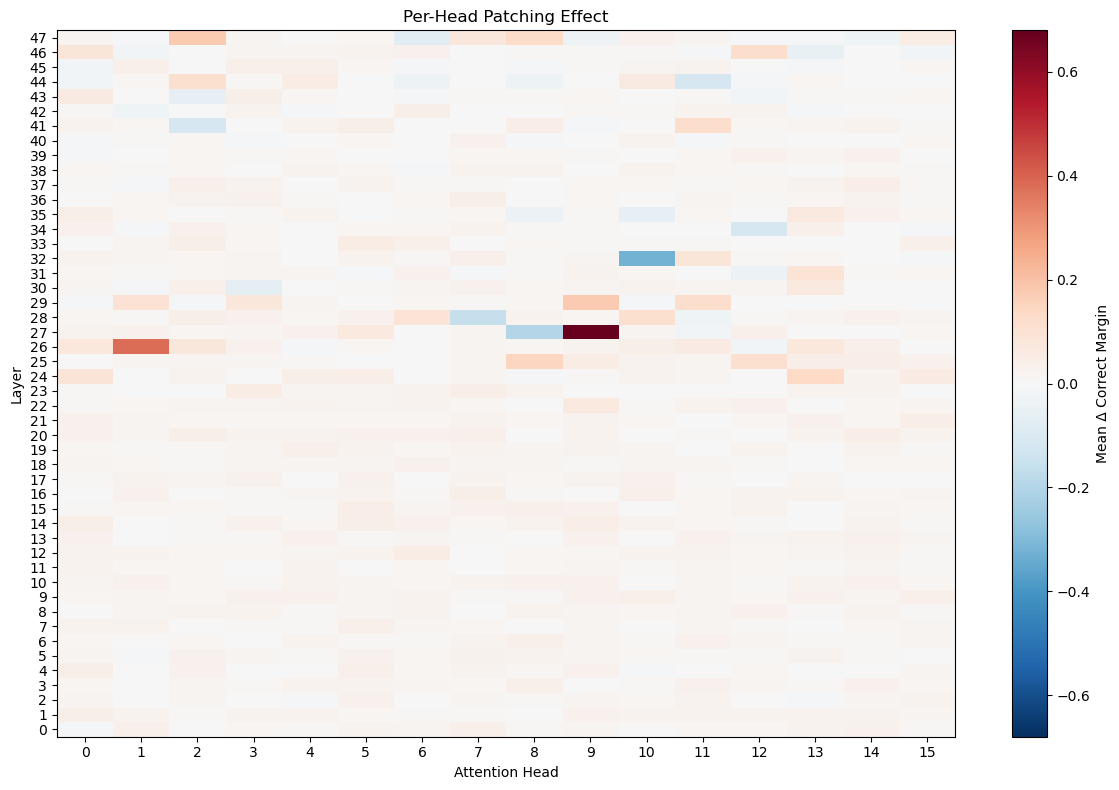

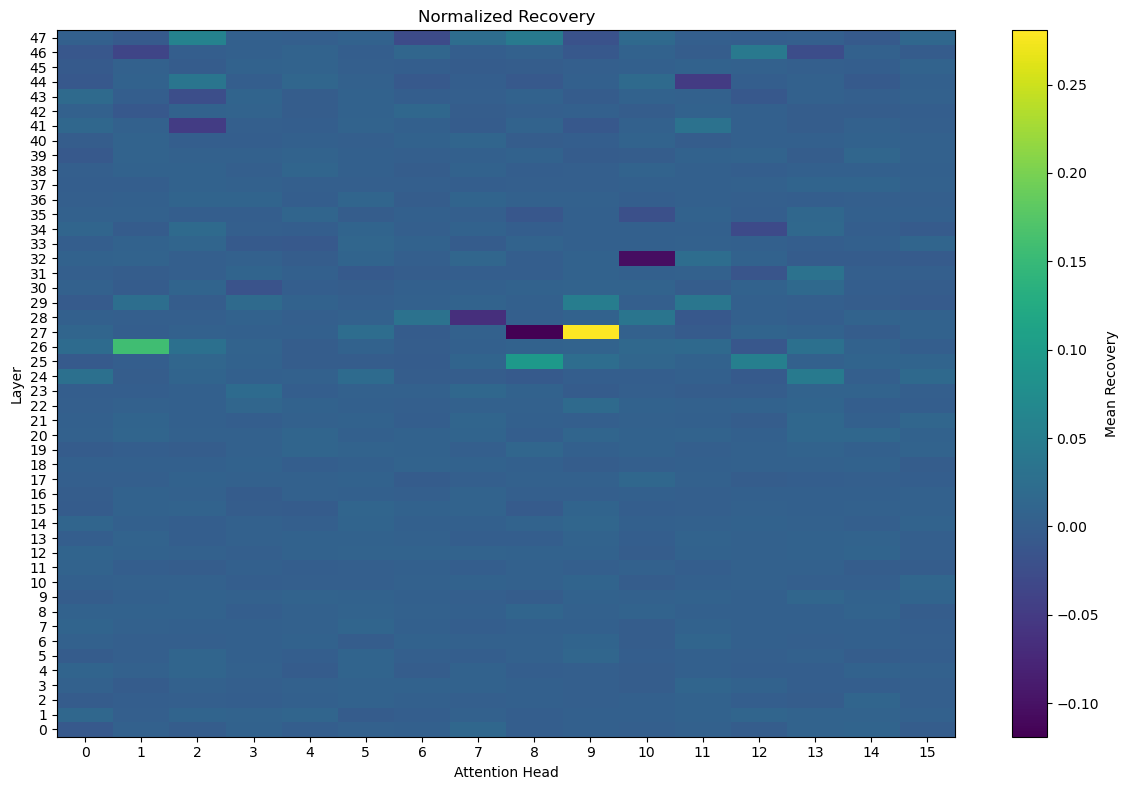

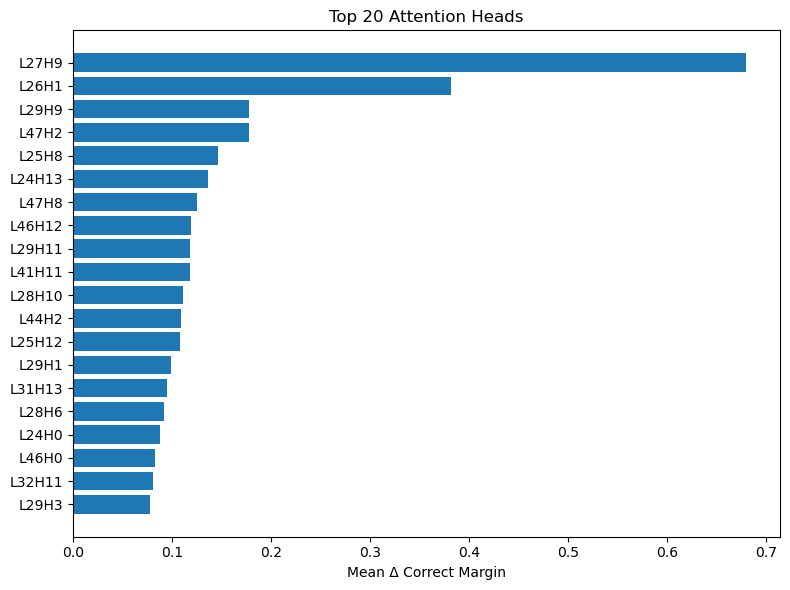

,layer,head,delta_margin,recovery
441,27,9,0.68000,0.280667
417,26,1,0.38125,0.158116
473,29,9,0.17750,0.050301
754,47,2,0.17750,0.057768
408,25,8,0.14625,0.095492
397,24,13,0.13625,0.046470
760,47,8,0.12500,0.045267
748,46,12,0.11875,0.042370
475,29,11,0.11750,0.038356
667,41,11,0.11750,0.031639


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt



csv = "/oscar/data/epavlick/aparasel/Binding-Problem-Brown/Results/conj_headpatch_all_in_one.csv"

df = pd.read_csv(csv)

# Keep only successful patches
if "error" in df.columns:
    df = df[df["error"].isna()].copy()



summary = (
    df.groupby(["layer", "head"], as_index=False)
      .agg(
          delta_margin=("delta_margin", "mean"),
          recovery=("recovery", "mean"),
      )
)



delta = summary.pivot(
    index="layer",
    columns="head",
    values="delta_margin",
).sort_index().sort_index(axis=1)

recovery = summary.pivot(
    index="layer",
    columns="head",
    values="recovery",
).sort_index().sort_index(axis=1)

plt.figure(figsize=(12,8))

v = np.nanmax(np.abs(delta.values))

plt.imshow(
    delta.values,
    origin="lower",
    aspect="auto",
    cmap="RdBu_r",
    vmin=-v,
    vmax=v,
)

plt.colorbar(label="Mean Δ Correct Margin")

plt.xlabel("Attention Head")
plt.ylabel("Layer")
plt.title("Per-Head Patching Effect")

plt.xticks(
    np.arange(len(delta.columns)),
    delta.columns,
)

plt.yticks(
    np.arange(len(delta.index)),
    delta.index,
)

plt.tight_layout()
plt.show()

plt.figure(figsize=(12,8))

plt.imshow(
    recovery.values,
    origin="lower",
    aspect="auto",
    cmap="viridis",
)

plt.colorbar(label="Mean Recovery")

plt.xlabel("Attention Head")
plt.ylabel("Layer")
plt.title("Normalized Recovery")

plt.xticks(
    np.arange(len(recovery.columns)),
    recovery.columns,
)

plt.yticks(
    np.arange(len(recovery.index)),
    recovery.index,
)

plt.tight_layout()
plt.show()


top = (
    summary.sort_values(
        "delta_margin",
        ascending=False,
    )
    .head(20)
    .copy()
)

plt.figure(figsize=(8,6))

labels = [
    f"L{l}H{h}"
    for l, h in zip(top["layer"], top["head"])
]

plt.barh(
    labels[::-1],
    top["delta_margin"].values[::-1],
)

plt.xlabel("Mean Δ Correct Margin")
plt.title("Top 20 Attention Heads")

plt.tight_layout()
plt.show()

display(top)

# Qwen

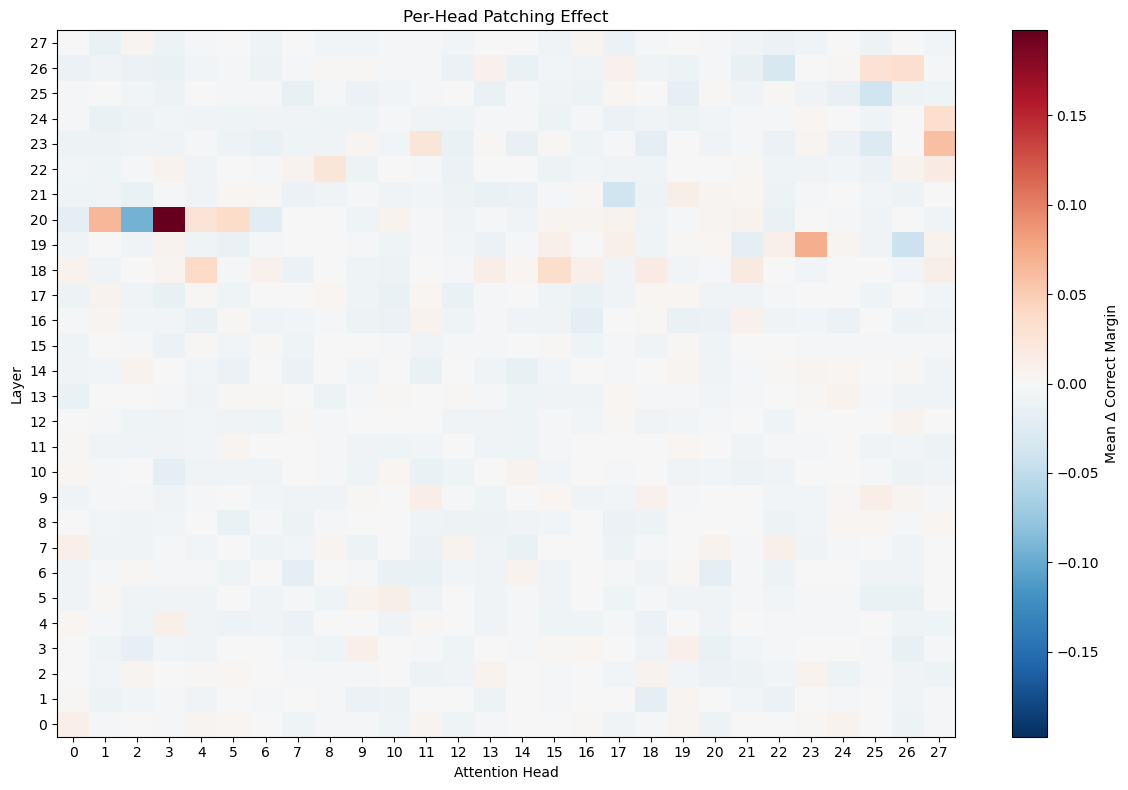

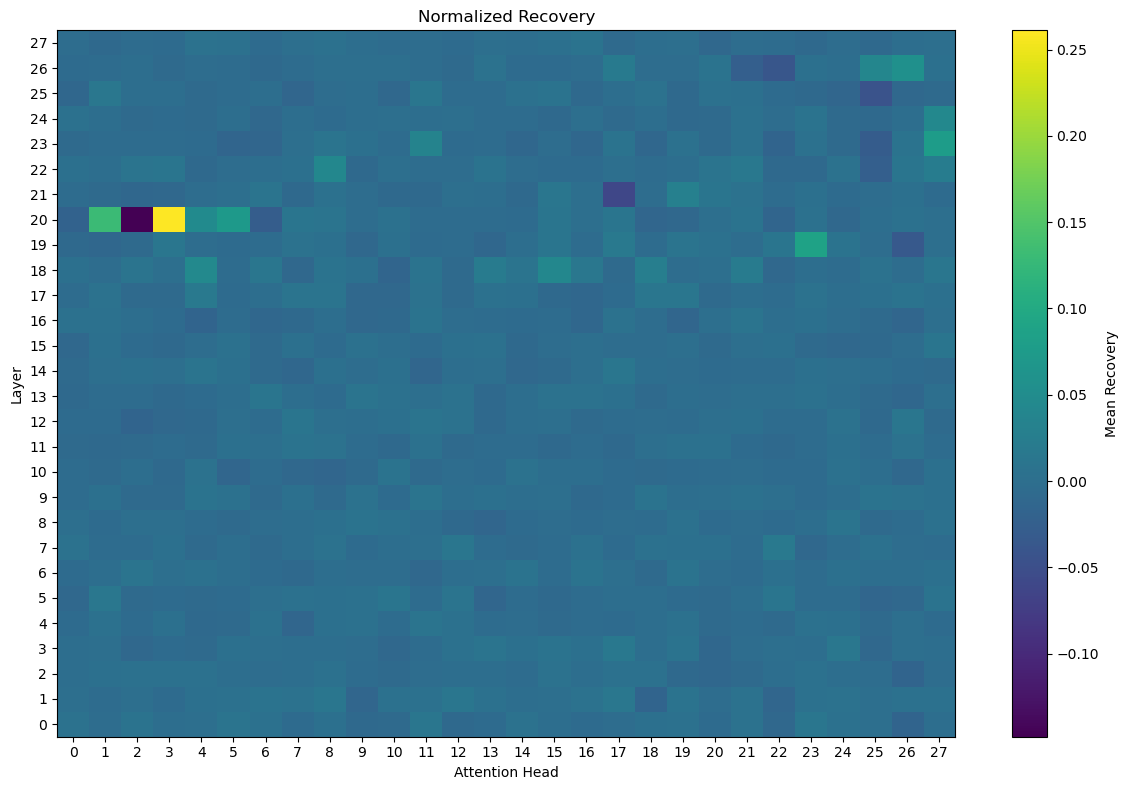

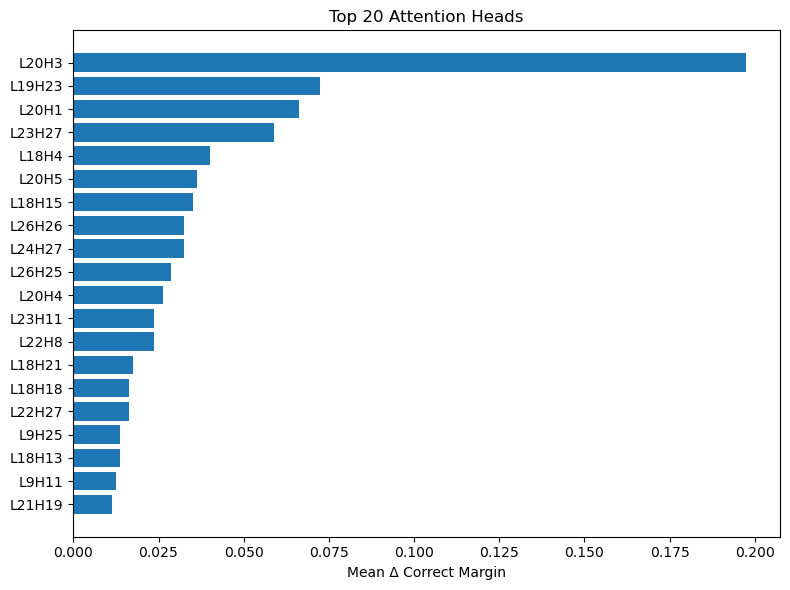

,layer,head,delta_margin,recovery
563,20,3,0.19750,0.261117
555,19,23,0.07250,0.088350
561,20,1,0.06625,0.131284
671,23,27,0.05875,0.077652
508,18,4,0.04000,0.044426
565,20,5,0.03625,0.071421
519,18,15,0.03500,0.041076
754,26,26,0.03250,0.057448
699,24,27,0.03250,0.042703
753,26,25,0.02875,0.039339


In [2]:


csv = "/oscar/data/epavlick/aparasel/Binding-Problem-Brown/Results/conj_headpatch_all_in_one_qwen.csv"

df = pd.read_csv(csv)

# Keep only successful patches
if "error" in df.columns:
    df = df[df["error"].isna()].copy()


summary = (
    df.groupby(["layer", "head"], as_index=False)
      .agg(
          delta_margin=("delta_margin", "mean"),
          recovery=("recovery", "mean"),
      )
)


delta = summary.pivot(
    index="layer",
    columns="head",
    values="delta_margin",
).sort_index().sort_index(axis=1)

recovery = summary.pivot(
    index="layer",
    columns="head",
    values="recovery",
).sort_index().sort_index(axis=1)


plt.figure(figsize=(12,8))

v = np.nanmax(np.abs(delta.values))

plt.imshow(
    delta.values,
    origin="lower",
    aspect="auto",
    cmap="RdBu_r",
    vmin=-v,
    vmax=v,
)

plt.colorbar(label="Mean Δ Correct Margin")

plt.xlabel("Attention Head")
plt.ylabel("Layer")
plt.title("Per-Head Patching Effect")

plt.xticks(
    np.arange(len(delta.columns)),
    delta.columns,
)

plt.yticks(
    np.arange(len(delta.index)),
    delta.index,
)

plt.tight_layout()
plt.show()


plt.figure(figsize=(12,8))

plt.imshow(
    recovery.values,
    origin="lower",
    aspect="auto",
    cmap="viridis",
)

plt.colorbar(label="Mean Recovery")

plt.xlabel("Attention Head")
plt.ylabel("Layer")
plt.title("Normalized Recovery")

plt.xticks(
    np.arange(len(recovery.columns)),
    recovery.columns,
)

plt.yticks(
    np.arange(len(recovery.index)),
    recovery.index,
)

plt.tight_layout()
plt.show()


top = (
    summary.sort_values(
        "delta_margin",
        ascending=False,
    )
    .head(20)
    .copy()
)

plt.figure(figsize=(8,6))

labels = [
    f"L{l}H{h}"
    for l, h in zip(top["layer"], top["head"])
]

plt.barh(
    labels[::-1],
    top["delta_margin"].values[::-1],
)

plt.xlabel("Mean Δ Correct Margin")
plt.title("Top 20 Attention Heads")

plt.tight_layout()
plt.show()

display(top)

In [5]:
print(len(df))
print(df["trial"].nunique())
print(sorted(df["trial"].unique()))

9000
12
[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]
